# Supplementary Fig. 8: Dependence of LPFC subregions' activity on outcome history

[AI generated summary] Same analysis as Fig. 4b (`fig4ab_composite_session.ipynb`), for the two LPFC subregions. All units are pooled into a composite session (20 trials for each history of the last three outcomes, for each unit). A feedback decoder is trained at each time point (10-fold cross-validation), and the population activity projected to its decision vector subspace (DVS) is averaged by the history of the last three outcomes: dLPFC (left) and vLPFC (right) dynamics in the DVS (MCC: Fig. 4b).

**How to run:** first build the composite session: `python run_build_composite_session.py meta_rates_history` in this folder (several hours; saved in `results/composite_sessions/`, it is not shared). The trials of the composite session are sampled randomly, so the results differ slightly from those of the paper. Then run all cells (a few minutes). Figures are saved in `figs/`. The titles, the event labels and the shaded period of interest of the paper figure were added when the figure was assembled.

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
from helpers_neural_value import *
from helpers import load_mega_custom
from popy.config import COLORS

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Feedback decoding in the composite session

In [3]:
neural_dataset_all = load_mega_custom(downsample=True)

# create a new figure: the accuracies across areas

decodabilities = {}
for subregion in ['dLPFC', 'vLPFC']:  # LPFC subregions (Supplementary Fig. 8; MCC: Fig. 4b, see fig4ab_composite_session.ipynb)
    neural_dataset_subregion = neural_dataset_all.sel(unit=neural_dataset_all.subregion==subregion)
    ## 1. plot monkey average
    #results, weights, data_projected, pvalue = time_resolved_decoder(neural_dataset, target='R_1', t_project=t_interest_fit)
    decodability_matrix, data_projected = time_resolved_decoder_all_time(neural_dataset_subregion, target='R_1', across_time=False)

    decodabilities[str(subregion)] = data_projected

Removed 332 units with mean firing rate < 1 Hz


---
# Supplementary Fig. 8, dLPFC and vLPFC dynamics in the DVS

dLPFC
vLPFC


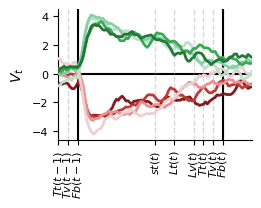

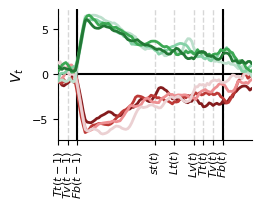

In [4]:
for subregion, data in decodabilities.items():    
    print(subregion)
    fig2, ax2 = plot_projected_data(data, t_interest_value=None, n_extra_trials=(-1, 0), paper_format=True, xlim=[-5, 5])

    # save as svgs
    fig2.savefig(os.path.join(FIGS_PATH, f'figS8_{subregion}_neural_value.svg'), bbox_inches='tight', transparent=True)

In [5]:
# Export source data (Supplementary Figure 8)
from popy.source_data import export_source_data
from scipy import ndimage

# dLPFC (left) and vLPFC (right), same averaging and smoothing as in plot_projected_data(): mean projection of the trials of
# each history of the last three outcomes, moving average over 0.5 s, in the displayed time window
sign_sd = {0: '-', 1: '+'}
tables_s8, n_units_s8, n_trials_s8 = {}, {}, {}
for subregion_sd, data_projected_sd in decodabilities.items():
    t_vec = data_projected_sd.time.values
    in_view = (t_vec >= -5 - 1e-6) & (t_vec <= 5 + 1e-6)
    window_sd = np.ones(int(0.5 / (t_vec[1] - t_vec[0])))
    window_sd = window_sd / len(window_sd)
    table_sd = pd.DataFrame({'Time (s)': t_vec[in_view]})
    for fb_sequence_sd in np.sort(np.unique(data_projected_sd.fb_sequence.data)):
        # history code = 4 x outcome(t) + 2 x outcome(t-1) + outcome(t-2), 1: rewarded (legend: t-2, t-1, t)
        r_t, r_t1, r_t2 = int(fb_sequence_sd) // 4, (int(fb_sequence_sd) // 2) % 2, int(fb_sequence_sd) % 2
        class_mean_sd = np.mean(data_projected_sd.where(data_projected_sd.fb_sequence == fb_sequence_sd), axis=0)
        class_mean_sd = ndimage.convolve(class_mean_sd, window_sd, mode='nearest')
        table_sd[f'Neural value, outcomes (t-2, t-1, t) = ({sign_sd[r_t2]}, {sign_sd[r_t1]}, {sign_sd[r_t]}) (arb. units)'] = class_mean_sd[in_view]
    tables_s8[f'{subregion_sd} dynamics in DVS'] = table_sd
    n_units_s8[subregion_sd] = int((neural_dataset_all.subregion.values == subregion_sd).sum())
    n_trials_s8[subregion_sd] = np.unique(data_projected_sd.fb_sequence.values, return_counts=True)[1].min()

assert len(set(n_trials_s8.values())) == 1
export_source_data(
    'Supplementary Figure 8',
    tables_s8,
    'Population activity of the dLPFC (left) and vLPFC (right) composite sessions (units of all sessions of both monkeys pooled; '
    f'dLPFC: {n_units_s8["dLPFC"]}, vLPFC: {n_units_s8["vLPFC"]} units) projected onto the decision vector subspace (DVS) of the '
    'feedback decoder (decision value of the logistic regression decoder of the outcome of trial t trained at each time point, on '
    'the test trials of the 10-fold cross-validation; neural value, arbitrary units), averaged over the trials with the same history '
    f'of the last three outcomes (t-2, t-1, t; +: rewarded, -: unrewarded; {n_trials_s8["dLPFC"]} trials per history), moving '
    'average over 0.5 s. Time: time-normalized trial time (s), Tt(t) = -5 s, Fb(t) = -4 s, Lt(t+1) = 1 s, Tt(t+1) = 2.5 s, '
    'Fb(t+1) = 3.5 s. No error bars. MCC: Figure 4b.')

Supplementary Figure 8: source data saved (101 rows, 101 rows)
